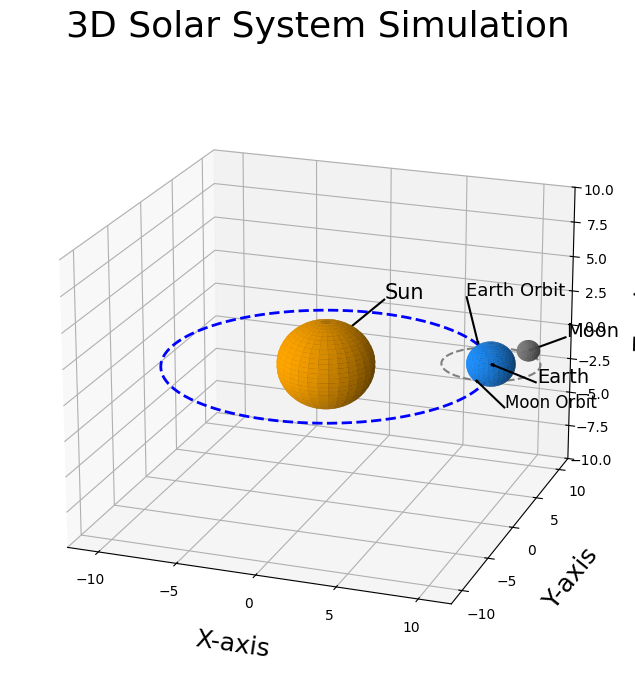

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# ================================
# Create Figure
# ================================
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection='3d')

# ================================
# Parameters
# ================================
earth_orbit_radius = 10
moon_orbit_radius = 3.0

# Earth position
earth_angle = np.deg2rad(20)

earth_x = earth_orbit_radius * np.cos(earth_angle)
earth_y = earth_orbit_radius * np.sin(earth_angle)
earth_z = 0

# Moon position
moon_angle = np.deg2rad(-25)

moon_x = earth_x + moon_orbit_radius*np.cos(moon_angle)
moon_y = earth_y + moon_orbit_radius*np.sin(moon_angle)
moon_z = 1.8

# ================================
# Draw Sphere Function
# ================================
def draw_sphere(center, radius, color):

    u = np.linspace(0,2*np.pi,60)
    v = np.linspace(0,np.pi,30)

    x = radius*np.outer(np.cos(u),np.sin(v))
    y = radius*np.outer(np.sin(u),np.sin(v))
    z = radius*np.outer(np.ones(np.size(u)),np.cos(v))

    ax.plot_surface(
        x+center[0],
        y+center[1],
        z+center[2],
        color=color,
        linewidth=0,
        shade=True
    )

# ================================
# Sun
# ================================
draw_sphere((0,0,0),3.0,'orange')

# ================================
# Earth
# ================================
draw_sphere((earth_x,earth_y,earth_z),1.5,'dodgerblue')

# ================================
# Moon
# ================================
draw_sphere((moon_x,moon_y,moon_z),0.7,'gray')

# ================================
# Earth Orbit
# ================================
t = np.linspace(0,2*np.pi,400)

ax.plot(
    earth_orbit_radius*np.cos(t),
    earth_orbit_radius*np.sin(t),
    np.zeros_like(t),
    '--',
    color='blue',
    linewidth=2,
    label='Earth Orbit'
)

# ================================
# Moon Orbit
# ================================
ax.plot(
    earth_x+moon_orbit_radius*np.cos(t),
    earth_y+moon_orbit_radius*np.sin(t),
    np.zeros_like(t),
    '--',
    color='gray',
    linewidth=1.5,
    label='Moon Orbit'
)

# ================================
# Labels
# ================================
# Sun label
sun_label = (2.8, 2.8, 4.0)
ax.text(*sun_label, "Sun", fontsize=15, color='black')

# Earth label
earth_label = (earth_x + 3.2, earth_y - 1.0, earth_z - 0.5)
ax.text(*earth_label, "Earth", fontsize=14)

# Moon label
moon_label = (moon_x + 2.0, moon_y + 1.2, moon_z + 0.8)
ax.text(*moon_label, "Moon", fontsize=14)

# Earth Orbit label
orbit_label = (6.5, 7.5, 3)
ax.text(*orbit_label, "Earth Orbit", fontsize=13, color='black')

# Moon Orbit label
moon_orbit_label = (earth_x + 2.0, earth_y - 3.5, -1.5)
ax.text(*moon_orbit_label, "Moon Orbit", fontsize=12, color='black')


# ================================
# Arrows
# ================================

# Arrow: Sun
ax.quiver(
    sun_label[0], sun_label[1], sun_label[2],
    -2.8, -2.8, -2.8,
    color='black',
    arrow_length_ratio=0.08,
    linewidth=1.5
)

# Arrow: Earth
ax.quiver(
    earth_label[0], earth_label[1], earth_label[2],
    earth_x-earth_label[0],
    earth_y-earth_label[1],
    earth_z-earth_label[2],
    color='black',
    arrow_length_ratio=0.08,
    linewidth=1.5
)

# Arrow: Moon
ax.quiver(
    moon_label[0], moon_label[1], moon_label[2],
    moon_x-moon_label[0],
    moon_y-moon_label[1],
    moon_z-moon_label[2],
    color='black',
    arrow_length_ratio=0.10,
    linewidth=1.5
)

# Arrow: Earth Orbit
orbit_point = (
    earth_orbit_radius*np.cos(np.deg2rad(40)),
    earth_orbit_radius*np.sin(np.deg2rad(40)),
    0
)

ax.quiver(
    orbit_label[0], orbit_label[1], orbit_label[2],
    orbit_point[0]-orbit_label[0],
    orbit_point[1]-orbit_label[1],
    orbit_point[2]-orbit_label[2],
    color='black',
    arrow_length_ratio=0.08,
    linewidth=1.5
)

# Arrow: Moon Orbit
moon_orbit_point = (
    earth_x,
    earth_y - moon_orbit_radius,
    0
)

ax.quiver(
    moon_orbit_label[0], moon_orbit_label[1], moon_orbit_label[2],
    moon_orbit_point[0]-moon_orbit_label[0],
    moon_orbit_point[1]-moon_orbit_label[1],
    moon_orbit_point[2]-moon_orbit_label[2],
    color='black',
    arrow_length_ratio=0.08,
    linewidth=1.5
)

# ================================
# Formatting
# ================================
ax.set_title("3D Solar System Simulation",fontsize=26,pad=20)

ax.set_xlabel("X-axis",fontsize=18,labelpad=15)
ax.set_ylabel("Y-axis",fontsize=18,labelpad=15)
ax.set_zlabel("Z-axis",fontsize=18,labelpad=15)

ax.set_xlim(-12,12)
ax.set_ylim(-12,12)
ax.set_zlim(-10,10)

ax.view_init(elev=20, azim=-70)

plt.tight_layout()
plt.show()